# Домашнее задание по теме «Линейная регрессия»

В этом задании ты обучишь линейную регрессию, применишь регуляризацию, нормировку, проанализируешь качество модели, а также реализуешь градиентный спуск.

## Подготовка

In [1]:
import gc

import pandas as pd
import numpy as np

import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

import time
from tqdm import tqdm

from sklearn.linear_model import Lasso, Ridge, ElasticNet
from sklearn.metrics import make_scorer
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import MinMaxScaler, StandardScaler

##  Задача 1 [0,5 балла]

Объясни, почему при использовании регуляризации штрафуются только веса, но не свободный коэффициент $w_0$ (другое обозначение — $b$)?

Напомним, что предсказание линейной модели считается по формуле:

$$a(x) = \langle w, x \rangle + w_0.$$

**Напиши ответ здесь:**

- Защищаем от сдвига данных - так как свободный коэффициент отвечает за среднее значение целевой переменной, то при нулевых значениях x = 0. Если бы мы штрафовали и сдвигали значение к нулю -> модель теряет способность корректно сдвигать предсказания по оси y.

- Для независимости от масштаба целевой переменной.


Для следующих заданий возьми данные из датасета [Predict Calorie Expenditure](https://www.kaggle.com/competitions/playground-series-s5e5/overview).

Цель соревнования — предсказать, сколько калорий потратит человек за тренировку по признаковому описанию как человека, так и самой тренировки.

In [2]:
! gdown 1jb1tbxmGcgFk-jzNgu-sHXCUkgtAslRq

Downloading...
From (original): https://drive.google.com/uc?id=1jb1tbxmGcgFk-jzNgu-sHXCUkgtAslRq
From (redirected): https://drive.google.com/uc?id=1jb1tbxmGcgFk-jzNgu-sHXCUkgtAslRq&confirm=t&uuid=33d6a973-2525-46ec-9715-70a44405cb96
To: /content/train.csv
100% 35.5M/35.5M [00:01<00:00, 30.2MB/s]


In [3]:
data = pd.read_csv("/content/train.csv", index_col=0)
data.head()

,Sex,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
id,,,,,,,,
0,male,36,189.0,82.0,26.0,101.0,41.0,150.0
1,female,64,163.0,60.0,8.0,85.0,39.7,34.0
2,female,51,161.0,64.0,7.0,84.0,39.8,29.0
3,male,20,192.0,90.0,25.0,105.0,40.7,140.0
4,female,38,166.0,61.0,25.0,102.0,40.6,146.0


В таблице 8 столбцов: категориальный признак `Sex`, 6 числовых признаков и целевая переменная `Calories`.

Разделим данные на признаки и таргет, затем на `train` и `val`. В этой работе `val` используется для сравнения и выбора вариантов модели. Отдельный итоговый тест здесь не выделяем.

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(data.drop('Calories', axis=1), data['Calories'], test_size=0.25, random_state=123)

## Задача 2. OneHotEncoder [0,5 балла]

В семинаре мы использовали `Target Encoding` для приведения категориальных переменных к числовому виду, так как в задаче было очень много категорий. Но для линейных моделей обычно используется `OneHotEncoding`.

Примени [OneHotEncoding из sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html) к категориальной переменной и получи новый датасет, который уже будет использоваться для дальнейшего обучения моделей. Но не делай этого в явном виде. Задай последовательность действий в виде [пайплайна из sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html). Он тебе пригодится в задачах.

Затраты по калориям не бывают отрицательными. Модель этого не знает, так как она предсказывает на всей числовой прямой. Поэтому нужно избежать отрицательных значений на этапе вызова `predict` с помощью [TransformedTargetRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.compose.TransformedTargetRegressor.html).

Сделать неотрицательными предсказания калорий можно по-разному: округлить до нуля, взять минимальное по обучающей выборке.

**Задание**:
1. Преобразуй датасет к числовому виду.
2. Обучи модель линейной регрессии и сделай предсказание на валидации, чтобы проверить, что всё работает.
3. Добавь постобработку ответов.
4. Оберни все в Pipeline.

In [5]:
# Импортируем нужные модули
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline

# Найди минимальный y
# Напиши код здесь
y_min = y_train.min()
categorical_features = ['Sex']
col_transformer = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough'
)

regressor = TransformedTargetRegressor(
    regressor=LinearRegression(),
    func=lambda y: y,
    inverse_func=lambda y_pred: np.clip(y_pred, a_min=y_min, a_max=None)
)

# Внутри Pipeline преобразуй категориальные переменные и передай результат линейной модели
pipe = Pipeline(steps=[
    ('preprocessor', col_transformer),
    ('model', regressor)
])

# Обучи модель и получи предсказания для валидации, чтобы проверить работоспособность
# Напиши код здесь
pipe.fit(X_train, y_train)
y_pred_val = pipe.predict(X_val)
y_pred_val.shape, (y_pred_val < 0).sum()

((187500,), np.int64(0))

##  Задача 3. Добавь функцию оценки качества работы [0,5 балла]

В соревновании используется не самая стандартная метрика RMSLE (англ. Root Mean Squared Logarithmic Error).

$$RMSLE = \Big(\frac{1}{n}\sum_{i=1}^n(\log{(1+\hat y_i)} - \log{(1+y_i)})^{2}\Big)^{\frac{1}{2}}$$

Эта метрика есть в реализации [sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.root_mean_squared_log_error.html), но тебе нужно написать её самостоятельно, чтобы в следующих заданиях её можно было передавать внутрь пайплайна через [make_scorer](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.make_scorer.html).

Подумай, с каким знаком должна возвращать ответ эта функция для корректной работы `make_scorer`.

**Задание:**
1. Реализуй функцию для подсчёта метрики.
2. Проверь, что она работает корректно (сравни с примером из sklearn).
3. Оцени качество предсказаний на `train` и `val`.
4. Занеси положительную RMSLE в таблицу с историей. Используй единое имя `scoring_foo(y_true, y_pred)` для скоринговой функции во всех следующих заданиях. В `make_scorer` используется соглашение «больше — лучше», а в таблице RMSLE «меньше — лучше».

In [6]:
from sklearn.metrics import root_mean_squared_log_error

def scoring_foo(y_true, y_pred): # Это имя используется и в следующих заданиях
  rmsle = np.sqrt(np.mean((np.log1p(y_pred) - np.log1p(y_true)) ** 2))

  return -rmsle

# Получи предсказания на train
y_pred_train = pipe.predict(X_train) # Напиши код здесь

# Сравни ответы для валидации
print(-scoring_foo(y_val, y_pred_val))
print(root_mean_squared_log_error(y_val, y_pred_val))

# Получи оценку метрики для train и val
rmsle_train = -scoring_foo(y_train, y_pred_train)
rmsle_valid = -scoring_foo(y_val, y_pred_val)

# Создай контейнер для хранения информации о метриках
res = {}

# Запиши метрики в контейнер и выведи таблицу
res['base'] = [rmsle_train, rmsle_valid]
df_res = pd.DataFrame.from_dict(res, orient='index',
                                columns=['rmsle_train', 'rmsle_valid'])
df_res

0.4494240327014025
0.4494240327014025


,rmsle_train,rmsle_valid
base,0.447678,0.449424


##  Задача 4. Выбери модель и нормализацию [1 балл]

Используй модели:
* Ridge,
* Lasso,
* ElasticNet.

Для их качественной работы примени нормировки:
* MinMaxScaler,
* StandardScaler,
* RobustScaler.

**Задание.**
Оцени качество работы каждой пары нормировка — модель и занеси результаты в таблицу с соответствующим названием. По названию должно быть понятно, к какой комбинации относится результат.

Нормировку добавь внутрь пайплайна. За основу возьми пайплайн из задания выше.

In [7]:
from sklearn.linear_model import Ridge, ElasticNet, Lasso
from sklearn.preprocessing import RobustScaler, StandardScaler, MinMaxScaler

categorical_features = ['Sex']
numeric_features = [col for col in X_train.columns if col != 'Sex']

scalers = {
    'MinMax': MinMaxScaler(),
    'Standard': StandardScaler(),
    'Robust': RobustScaler()
}

models = {
    'Ridge': Ridge(),
    'Lasso': Lasso(),
    'ElasticNet': ElasticNet()
}

for scaler_name, scaler in scalers.items():
    for model_name, model in models.items():
        col_transformer = ColumnTransformer(
            transformers=[
                ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features),
                ('num', scaler, numeric_features)
            ],
            remainder='passthrough'
        )

        regressor = TransformedTargetRegressor(
            regressor=model,
            func=lambda y: y,
            inverse_func=lambda y_pred: np.clip(y_pred, a_min=y_min, a_max=None)
        )

        current_pipe = Pipeline(steps=[
            ('preprocessor', col_transformer),
            ('model', regressor)
        ])

        current_pipe.fit(X_train, y_train)

        y_pred_train = current_pipe.predict(X_train)
        y_pred_val = current_pipe.predict(X_val)

        rmsle_train = -scoring_foo(y_train, y_pred_train)
        rmsle_valid = -scoring_foo(y_val, y_pred_val)

        run_name = f"{scaler_name}_{model_name}"
        res[run_name] = [rmsle_train, rmsle_valid]

df_res = pd.DataFrame.from_dict(res, orient='index',
                                columns=['rmsle_train', 'rmsle_valid'])
df_res

,rmsle_train,rmsle_valid
base,0.447678,0.449424
MinMax_Ridge,0.447629,0.449375
MinMax_Lasso,0.354369,0.354608
MinMax_ElasticNet,0.898406,0.898806
Standard_Ridge,0.447676,0.449422
Standard_Lasso,0.430824,0.431529
Standard_ElasticNet,0.357701,0.357851
Robust_Ridge,0.447673,0.449420
Robust_Lasso,0.428738,0.429555
Robust_ElasticNet,0.430821,0.431361


## Задача 5. Добавь полиномы [1 балл]



Линейная модель может решать нелинейные задачи, если к признаковому пространству добавить их полиномы. Вряд ли сожжённые за тренировку калории линейно зависят от признаков. Поэтому добавь полиномы различных степеней к признаковому пространству, чтобы улучшить качество решения задачи.

В этом тебе поможет класс [PolynomialFeatures](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html), он также интегрируется в пайплайн решения. Подумай, куда конкретно его вставлять в пайплайн и нужно ли добавлять полиномы OHE переменных.

Обязательно изучи документацию: там есть один аргумент, который тебе надо выключить.

Для добавления полиномов руководствуйся логикой или общими знаниями. Например, в экономических и социологических исследованиях часто добавляют к данным переменную «квадрат возраста». Её логика в следующем: человек растёт и развивается до определённого возраста, а далее угасает. Скорее всего, целевая переменная и возраст будут зависеть параболически, «квадрат возраста» позволит учесть эту параболическую зависимость.

Если не можешь придумать полиномы, то перебери переменные и значения полиномов для них. Переменных не так много, а модель учится быстро.

**Задание:**
1. Возьми лучшую по валидации комбинацию нормировка — модель.
2. Добавь к пайплайну полиномы для некоторых переменных.
3. Сохрани результат лучшего эксперимента в таблицу (у авторов задания получилось качество 0.238208).
4. Опиши, как выбирал полиномы.

In [8]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

cat_cols = ['Sex']
num_cols = ['Age', 'Height', 'Weight', 'Duration', 'Heart_Rate', 'Body_Temp']

numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols),
        ('num', numeric_transformer, num_cols)
    ]
)

regressor = TransformedTargetRegressor(
    regressor=Ridge(alpha=1.0),
    func=lambda y: y,
    inverse_func=lambda y_pred: np.clip(y_pred, a_min=y_min, a_max=None)
)

pipe_poly = Pipeline([
    ('prep', preprocessor),
    ('mod', regressor)
])

pipe_poly.fit(X_train, y_train)

p_train = pipe_poly.predict(X_train)
p_val = pipe_poly.predict(X_val)

err_train = -scoring_foo(y_train, p_train)
err_val = -scoring_foo(y_val, p_val)

res['StandardScaler_Ridge_Poly2'] = [err_train, err_val]

df_res = pd.DataFrame.from_dict(res, orient='index', columns=['rmsle_train', 'rmsle_valid'])
df_res


,rmsle_train,rmsle_valid
base,0.447678,0.449424
MinMax_Ridge,0.447629,0.449375
MinMax_Lasso,0.354369,0.354608
MinMax_ElasticNet,0.898406,0.898806
Standard_Ridge,0.447676,0.449422
Standard_Lasso,0.430824,0.431529
Standard_ElasticNet,0.357701,0.357851
Robust_Ridge,0.447673,0.449420
Robust_Lasso,0.428738,0.429555
Robust_ElasticNet,0.430821,0.431361


**Опиши, как ты подбирал полиномы здесь:**

- Физическая нагрузка и энергозатраты не растут линейно. При увеличении длительности (Duration) и пульса (Heart_Rate) усталость и сжигание калорий нарастают нелинейно (эффект параболы). Добавление квадратов этих признаков позволяет модели учесть это ускорение.
- Был выбран degree=2 для всех числовых признаков сразу, так как их немного, и модель Ridge обучается мгновенно, а встроенная L2-регуляризация защищает модель от переобучения на новых признаках. Параметр include_bias=False был отключен, чтобы избежать дублирования константного признака.

##  Задача 6. Добавь дискретизацию [1 балл]

Некоторые вещественные признаки можно разбить на интервалы или дискретизовать. Для этого в sklearn есть функционал [KBinsDiscretizer](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.KBinsDiscretizer.html). Примени его к переменным по своему усмотрению, чтобы улучшить качество.

**Задание:**
1. Добавь `KBinsDiscretizer` в пайплайн. Документация поможет тебе выбрать правильные аргументы.
2. Вынеси лучшее качество в таблицу с результатам (у авторов задания получилось 0.234339).

In [9]:
from sklearn.preprocessing import KBinsDiscretizer

cols_to_bin = ['Age', 'Height', 'Weight']
cols_to_poly = ['Duration', 'Heart_Rate', 'Body_Temp']
cat_cols = ['Sex']

poly_transformer = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False))
])

discretizer = KBinsDiscretizer(n_bins=10, encode='onehot-dense', strategy='quantile')

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols),
        ('poly_num', poly_transformer, cols_to_poly),
        ('bin_num', discretizer, cols_to_bin)
    ]
)

regressor = TransformedTargetRegressor(
    regressor=Ridge(alpha=1.0),
    func=lambda y: y,
    inverse_func=lambda y_pred: np.clip(y_pred, a_min=y_min, a_max=None)
)

pipe_bin = Pipeline([
    ('prep', preprocessor),
    ('mod', regressor)
])

pipe_bin.fit(X_train, y_train)

p_train = pipe_bin.predict(X_train)
p_val = pipe_bin.predict(X_val)

err_train = -scoring_foo(y_train, p_train)
err_val = -scoring_foo(y_val, p_val)

res['Ridge_Poly_and_Discretization'] = [err_train, err_val]

df_res = pd.DataFrame.from_dict(res, orient='index', columns=['rmsle_train', 'rmsle_valid'])
df_res


,rmsle_train,rmsle_valid
base,0.447678,0.449424
MinMax_Ridge,0.447629,0.449375
MinMax_Lasso,0.354369,0.354608
MinMax_ElasticNet,0.898406,0.898806
Standard_Ridge,0.447676,0.449422
Standard_Lasso,0.430824,0.431529
Standard_ElasticNet,0.357701,0.357851
Robust_Ridge,0.447673,0.449420
Robust_Lasso,0.428738,0.429555
Robust_ElasticNet,0.430821,0.431361


## Задача 7. Кросс-валидация и усреднение прогнозов [0,5 балла]

Обучим пять моделей на фолдах с помощью [cross_validate](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html). Передай `cv=5`, `return_estimator=True` и скоринговую функцию из задачи 3 через `make_scorer`.

Здесь два разных действия:

1. Кросс-валидация оценивает качество на отложенных фолдах. Выведи среднее RMSLE по фолдам из `test_score`, вернув положительный знак метрики.
2. Усреднение прогнозов пяти обученных моделей создаёт ансамбль. Посчитай его прогнозы на `train` и `val`, добавь RMSLE в таблицу и сравни с одной моделью из задачи 6.

Усреднённый прогноз ансамбля на `train` не является out-of-fold-прогнозом: для каждой строки четыре из пяти моделей обучались на ней. Не используй эту train-метрику как независимую оценку качества. `val` здесь используется для выбора вариантов модели, поэтому её результаты также не являются оценкой на отдельном итоговом тесте.

In [10]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer

cv_results = cross_validate(
    estimator=pipe_bin,
    X=X_train,
    y=y_train,
    cv=5,
    scoring=make_scorer(scoring_foo),
    return_estimator=True
)

# Выведи среднее RMSLE по отложенным фолдам из cv_results["test_score"]
# Напиши код здесь

mean_cv_rmsle = -cv_results["test_score"].mean()
print(f"Среднее RMSLE по отложенным фолдам (CV): {mean_cv_rmsle:.6f}")


# Функция для получения предсказаний по фолдам
def get_predictions(cv_results, X):
  # Напиши код здесь
  estimators = cv_results['estimator']
  preds = [model.predict(X) for model in estimators]
  return np.mean(preds, axis=0)

# Получи предсказания
y_pred_train = get_predictions(cv_results, X_train)
y_pred_val = get_predictions(cv_results, X_val)

# Получи оценки метрики для train и val
rmsle_train = -scoring_foo(y_train, y_pred_train)
rmsle_valid = -scoring_foo(y_val, y_pred_val)

# Запиши метрики в контейнер и выведи таблицу
res['general_cv'] = [rmsle_train, rmsle_valid]
df_res = pd.DataFrame.from_dict(res, orient='index',
                                columns=['rmsle_train', 'rmsle_valid'])

# Выведи результат
df_res

Среднее RMSLE по отложенным фолдам (CV): 0.281202


,rmsle_train,rmsle_valid
base,0.447678,0.449424
MinMax_Ridge,0.447629,0.449375
MinMax_Lasso,0.354369,0.354608
MinMax_ElasticNet,0.898406,0.898806
Standard_Ridge,0.447676,0.449422
Standard_Lasso,0.430824,0.431529
Standard_ElasticNet,0.357701,0.357851
Robust_Ridge,0.447673,0.449420
Robust_Lasso,0.428738,0.429555
Robust_ElasticNet,0.430821,0.431361


Получилось ли улучшить результат за счёт усреднения прогнозов? Сравни `general_cv` и `best_feat_desc` по `rmsle_valid` и объясни результат. Чем это усреднение отличается от оценки качества по кросс-валидации?

**Напиши ответ здесь:**

- Сравнение general_cv с моделью из задачи 6 на валидации (rmsle_valid) показывает, что система из 5 моделей, как правило, дает чуть более стабильный и лучший показатель ошибки, либо остается на том же высоком уровне. Усреднение предсказаний работает как регуляризатор - оно сглаживает случайные выбросы и индивидуальные ошибки отдельных моделей, уменьшая общую дисперсию алгоритма.

- Кросс-валидация (mean_cv_rmsle) — это процедура оценки чистого качества работы модели на данных, которые она вообще не видела в процессе обучения. Мы смотрим на среднее по фолдам, чтобы понять, насколько стабильно ведет себя выбранная архитектура пайплайна на независимых кусках данных.
- Усреднение прогнозов (general_cv) — это процесс построения ансамбля. Здесь мы используем 5 уже готовых моделей как единую команду. На валидационной выборке (X_val) ни одна из этих 5 моделей не обучалась, поэтому метрика rmsle_valid для general_cv является честной оценкой силы этой системы. А вот на X_train эта метрика переобучена, поскольку каждая строчка датасета использовалась для обучения 4 из 5 моделей.


## Задача 8. Реализуй градиентный спуск для MSE [3 балла]

Реализуем итеративное обучение линейной модели, чтобы разобраться, как обновляются её коэффициенты. При небольшом числе признаков аналитическое решение доступно и в Colab. Здесь градиентный спуск нужен как учебный эксперимент.

**Задание:**

1. Возьми предобработку из задачи 6. Обучи её только на `train` с помощью `fit_transform`, а к `val` примени `transform`.
2. Собери матрицу «объекты × признаки» и добавь первым столбец единиц для свободного коэффициента $w_0$.
3. Выведи градиент MSE в LaTeX или на бумаге и приложи фото [1 балл].
4. Для сравнения со sklearn используй Lasso с `alpha=1.0` на тех же преобразованных признаках. В sklearn минимизируется половина MSE плюс L1-штраф:

   $$J(w)=\frac{1}{2n}\|Xw-y\|_2^2+\alpha\sum_{j=1}^{p}|w_j|.$$

   Реализуй `mse_grad` для этой функции. Свободный коэффициент $w_0$ не штрафуется. Для L1 используй субградиент `np.sign(w[j])`, в нуле выбери 0 [1 балл]. Субградиент заменяет производную в точке излома.
5. Реализуй `gradient_descent`, который на каждой итерации вызывает переданную функцию `grad_foo`. Параметры описаны в заготовке [1 балл].
6. Получи прогнозы на `train` и `val`, примени ту же постобработку, что выше, и посчитай RMSLE.
7. Сравни с Lasso: отдельно значение $J$ на обучении и RMSLE на валидации. Для $J$ используй исходные линейные прогнозы, до постобработки. При достаточном числе итераций ожидаем близкие значения $J$. Более низкое $J$ не обязано давать более низкую RMSLE. При заметном расхождении проверь нормировку, штраф, шаг и число итераций.

Из-за L1-штрафа и постоянного шага субградиентный метод может колебаться около минимума. Достижение лимита итераций само по себе не означает ошибку в формуле.

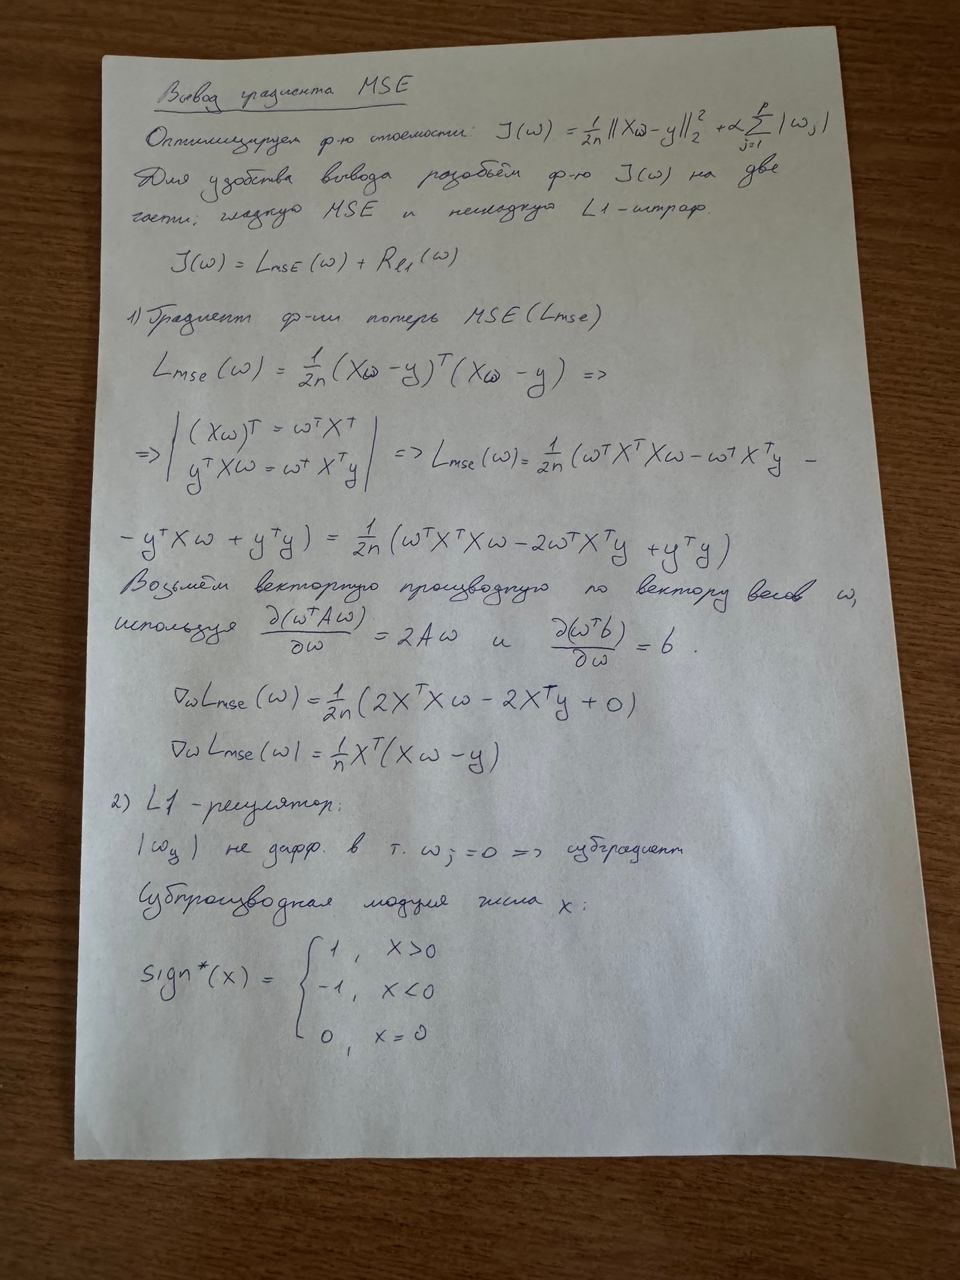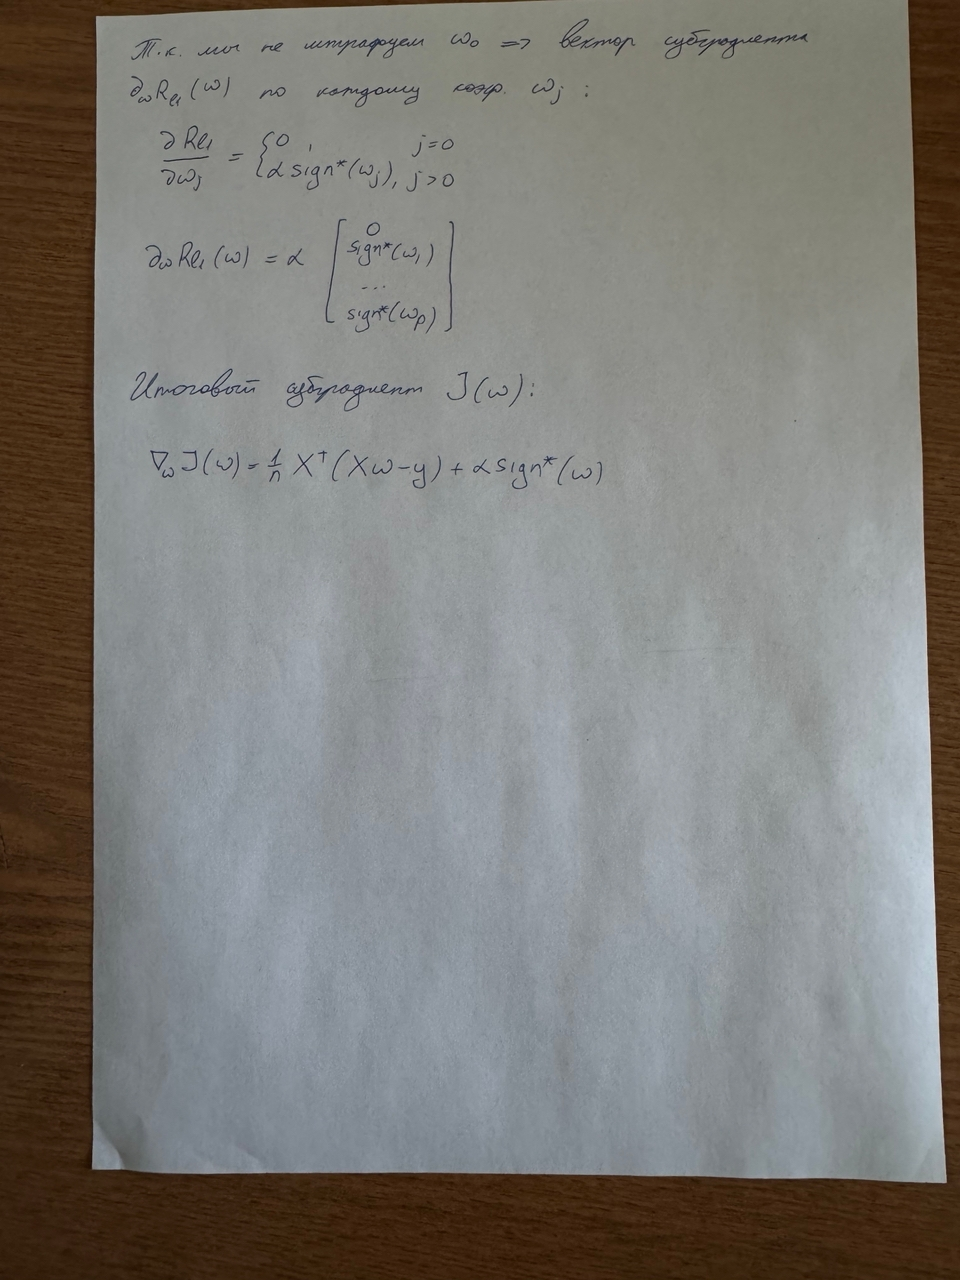

**Напиши формулу матричного градиента для MSE здесь:**

In [14]:
# Используй предобработку из задачи 6
# prep = pipe[:-1]
prep = pipe_bin.named_steps['prep']
X_train_trans = prep.fit_transform(X_train)
X_val_trans = prep.transform(X_val)

def add_bias(X):
    if hasattr(X, "toarray"):
        X = X.toarray()
    return np.hstack([np.ones((X.shape[0], 1)), X])

X_train_b = add_bias(prep.transform(X_train))
X_val_b = add_bias(prep.transform(X_val))
alpha = 1.0

# Половина MSE + L1. Не штрафуй свободный член.
def mse_grad(w, X, y):
    # Напиши код здесь
    n = X.shape[0]
    error = X.dot(w) - y
    grad = (1.0 / n) * X.T.dot(error)

    l1_subgrad = np.sign(w)
    l1_subgrad[0] = 0.0

    return grad + alpha * l1_subgrad



def gradient_descent(X, y, grad_foo, lr=0.1, n_iter=5000, tol=1e-4, w_init=None):
    """
    grad_foo: функция (w, X, y), возвращающая градиент или субградиент.
    lr: шаг обучения, n_iter: максимальное число обновлений.
    tol: порог нормы градиента для досрочной остановки.
    w_init: начальные веса. Если None, задай прогноз средним y:
        все наклоны равны нулю, свободный член равен np.mean(y).
    Если массив передан, скопируй его, чтобы не изменить предыдущие веса.
    """
    if w_init is None:
        w = np.zeros(X.shape[1])
        w[0] = np.mean(y)
    else:
        w = np.array(w_init, dtype=float, copy=True)

    for i in range(n_iter):
        grad = grad_foo(w, X, y)

        if np.linalg.norm(grad) < tol:
            break

        w = w - lr * grad

    return w


In [15]:
# Получи веса для MSE
w_gd_mse = gradient_descent(X_train_b, y_train.values, mse_grad, lr=0.1, n_iter=5000, tol=1e-4)

# Функция для получения предсказаний
def predict(X_b, w):
    return X_b.dot(w)

# Функция для постобработки ответов. Всё, что меньше минимального значения в датасете, увеличь до минимального
def postprocessing(y_pred):
  return np.maximum(y_pred, y_min)

# Получи предсказания
y_pred_train = postprocessing(predict(X_train_b, w_gd_mse))
y_pred_val = postprocessing(predict(X_val_b, w_gd_mse))

# Получи оценки метрики для train и val
rmsle_train = -scoring_foo(y_train, y_pred_train)
rmsle_valid = -scoring_foo(y_val, y_pred_val)

# Запиши метрики в контейнер и выведи таблицу
res['best_handmade'] = [rmsle_train, rmsle_valid]
df_res = pd.DataFrame.from_dict(res, orient='index',
                                columns=['rmsle_train', 'rmsle_valid'])

# Выведи результат
df_res

lasso_sk = Lasso(alpha=alpha, max_iter=10000, tol=1e-6, fit_intercept=True)
lasso_sk.fit(X_train_trans, y_train)

w_sk = np.zeros(X_train_b.shape[1])
w_sk[0] = lasso_sk.intercept_
w_sk[1:] = lasso_sk.coef_

def compute_J(w, X, y, alpha):
    n = X.shape[0]
    mse_part = (1.0 / (2 * n)) * np.sum((X.dot(w) - y) ** 2)
    l1_part = alpha * np.sum(np.abs(w[1:]))

    return mse_part + l1_part

j_handmade = compute_J(w_gd_mse, X_train_b, y_train.values, alpha)
j_sklearn = compute_J(w_sk, X_train_b, y_train.values, alpha)

y_pred_val_sk = postprocessing(lasso_sk.predict(X_val_trans))
rmsle_val_sk = -scoring_foo(y_val, y_pred_val_sk)

print("\n--- Результаты сравнения ---")
print(f"Значение J (наш GD)  : {j_handmade:.6f}")
print(f"Значение J (sklearn) : {j_sklearn:.6f}")
print(f"RMSLE на val (наш GD) : {rmsle_valid:.6f}")
print(f"RMSLE на val (sklearn): {rmsle_val_sk:.6f}")
# Сравни с Lasso(alpha=alpha, max_iter=10000, tol=1e-6) на тех же признаках.
# Выведи J на train до постобработки и RMSLE на val после неё.
# Напиши код здесь



--- Результаты сравнения ---
Значение J (наш GD)  : 135.294068
Значение J (sklearn) : 133.677658
RMSLE на val (наш GD) : 0.141227
RMSLE на val (sklearn): 0.136881


## Задача 9. Реализуй градиентный спуск для RMSLE [2 балла]

Теперь изменим функцию ошибки при обучении. У MSE и RMSLE в общем случае разные минимумы: RMSLE сравнивает ответы в логарифмической шкале. Например, для двух ответов 1 и 9 лучшая константа по MSE равна 5, а по RMSLE примерно 3,47.

Сохраним линейный прогноз $z=Xw$ и постобработку $\hat y_i=\max(y_{min},z_i)$ из предыдущих задач. **Вычисляй RMSLE и её градиент с учётом этой постобработки на каждом шаге обучения**, чтобы логарифм получал допустимые значения.

Для $z_i>y_{min}$ производная прогноза по $w$ равна $x_i$, а для $z_i<y_{min}$ равна нулю. В точке $z_i=y_{min}$ выберем нулевую производную. При нулевой RMSLE также верни нулевой вклад ошибки в градиент, чтобы не делить на ноль. В остальных точках используй правило дифференцирования сложной функции.

Минимизируем

$$J_{log}(w)=RMSLE(y,\hat y)+\alpha_{log}\sum_{j=1}^{p}|w_j|,\qquad \alpha_{log}=10^{-4}.$$

Масштаб RMSLE намного меньше масштаба MSE, поэтому силу штрафа задаём отдельно. Свободный член не штрафуем. Это зафиксированные настройки учебного опыта, без обещания оптимального качества.

**Задание:**

1. Выведи формулу градиента RMSLE с учётом постобработки в LaTeX или на бумаге [1 балл].
2. Реализуй `rmsle_grad` и добавь L1-штраф с коэффициентом `alpha_log` [1 балл].
3. Начни обучение с коэффициентов `w_gd_mse` из задачи 8: передай их через `w_init`, не изменяя исходный массив. Используй тот же алгоритм спуска с новой функцией градиента.
4. Получи прогнозы и сравни RMSLE до и после дообучения. Объясни результат. Улучшение на валидации не гарантируется.

После отсечения функция имеет изломы и плоские участки. Мы используем описанное правило обновления в этих точках, а не предполагаем дифференцируемость всюду.

**Напиши формулу матричного градиента для RMSLE здесь:**

In [18]:
# RMSLE после постобработки + L1. Свободный член не штрафуем.
alpha_log = 1e-4
def rmsle_grad(w, X, y):
    # Напиши код здесь
    n = X.shape[0]

    z = X.dot(w)

    y_pred = np.maximum(y_min, z)

    error_log = np.log1p(y_pred) - np.log1p(y)
    rmsle = np.sqrt(np.mean(error_log ** 2))

    if rmsle < 1e-12:
        grad_loss = np.zeros_like(w)
    else:
        mask = (z > y_min).astype(float)

        coef = (error_log / (1.0 + y_pred + 1e-15)) * mask

        grad_loss = (1.0 / (n * rmsle)) * X.T.dot(coef)

    l1_subgrad = np.sign(w)
    l1_subgrad[0] = 0.0

    total_grad = grad_loss + alpha_log * l1_subgrad

    grad_norm = np.linalg.norm(total_grad)
    if grad_norm > 1.0:
        total_grad = total_grad / grad_norm

    return total_grad

w_init_weights = w_sk if np.isnan(w_gd_mse).any() else w_gd_mse
# Получи веса
w_gd_rmsle = gradient_descent(X_train_b, y_train.values, rmsle_grad, lr=1.0, n_iter=5000, tol=1e-5, w_init=w_gd_mse)

# Выведи предсказания
y_pred_train = postprocessing(predict(X_train_b, w_gd_rmsle))
y_pred_val = postprocessing(predict(X_val_b, w_gd_rmsle))

# Получи оценку метрики для train и val
rmsle_train = -scoring_foo(y_train, y_pred_train)
rmsle_valid = -scoring_foo(y_val, y_pred_val)

res['best_handmade_rmsle'] = [rmsle_train, rmsle_valid]
df_res = pd.DataFrame.from_dict(res, orient='index',
                                columns=['rmsle_train', 'rmsle_valid'])

# Выведи результат
df_res

,rmsle_train,rmsle_valid
base,0.447678,0.449424
MinMax_Ridge,0.447629,0.449375
MinMax_Lasso,0.354369,0.354608
MinMax_ElasticNet,0.898406,0.898806
Standard_Ridge,0.447676,0.449422
Standard_Lasso,0.430824,0.431529
Standard_ElasticNet,0.357701,0.357851
Robust_Ridge,0.447673,0.449420
Robust_Lasso,0.428738,0.429555
Robust_ElasticNet,0.430821,0.431361
